In [1]:
"""
code to read the saved results from training/testing dataset
"""

'\ncode to read the saved results from training/testing dataset\n'

In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gsw
import pickle
import xarray as xr
from lo_tools import Lfun, zfun
import cmocean
from scipy.stats import pearsonr
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
Ldir = Lfun.Lstart()


In [3]:
import tensorflow as tf
from tensorflow.keras.models import load_model

2026-11-25 20:54:28.597333: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 20:54:28.641493: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
plt.rcdefaults()

In [5]:
plt.rcParams.update({
    'axes.labelsize': 18,          # Labels font size
    'xtick.labelsize': 15,         # X-axis ticks font size
    'ytick.labelsize': 15,         # Y-axis ticks font size
    'axes.labelweight': 'bold',    # Bold axis labels
    'xtick.direction': 'in',       # X-axis tick direction
    'ytick.direction': 'in',       # Y-axis tick direction
    'font.size': 15,               # Default font size for other text
})

In [6]:
# Load the saved model
add_hake_hpic = False
add_hake_hpic_trawl = True
cid_split = True
cast_balanced = True
z_fraction = True
benthic_aware = False
hypoxia_aware = False
hypoxia_shelf_aware = False
hypoxia_two_tier_shelf_aware = True
hypoxia_shelf_smooth_aware = False
remove_NO3 = True
add_3_feature = False

add_DO_gradient = False
add_SA_gradient = False
add_CT_gradient =  False

# add_SA_gradient = False
# add_SA_gradient = False
if add_hake_hpic:
    runame = 'with_hake_hpic'
    if cid_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
        if remove_NO3:
            name = 'cid_split_no_NO3'
        if add_CT_gradient and add_SA_gradient and add_DO_gradient:
            name += '_dDO_dz_dCT_dz_dSA_dz'
        elif add_DO_gradient:
            name += '_dDO_dz'
        elif add_CT_gradient:
            name += '_dCT_dz'
        elif add_SA_gradient:
            name += '_dSA_dz'
    else:
        name = ''
elif add_hake_hpic_trawl:
    runame = 'with_hake_hpic_trawl'
    if cid_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
            if cast_balanced and z_fraction:
                name += '_z_fraction'
            if cast_balanced and benthic_aware:
                name += '_benthic_aware'
            if cast_balanced and hypoxia_aware:
                name += '_hypoxia_aware'
            if cast_balanced and hypoxia_shelf_aware:
                name += '_hypoxia_shelf_aware1.2'
            if cast_balanced and hypoxia_shelf_smooth_aware:
                name += '_hypoxia_shelf_smooth_aware'
            if cast_balanced and hypoxia_two_tier_shelf_aware:
                name += '_hypoxia_two_tier_shelf_aware'
            if remove_NO3:
                name += '_no_NO3'
            if add_3_feature:
                name += 'add_3_feature'
    else:
        name = ''
else:
    runame = ''
    name = ''


In [7]:
# directory
in_dir = Ldir['LOo'] / 'LO_bias_corr' / 'keras' / runame / name

# define folder to hold figures
fig_dir0 = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / 'keras'
fig_dir = fig_dir0/ runame / name
Lfun.make_dir(fig_dir)

In [8]:
# Load the saved model
model = load_model(f'{in_dir}/DO_bias_corr.keras')
# read the data saved from training
fn = in_dir/'test_pred_data.p'
print(fn)

/b1/yifan/LO_output/LO_bias_corr/keras/with_hake_hpic_trawl/cid_split_cast_balanced_z_fraction_hypoxia_two_tier_shelf_aware_no_NO3/test_pred_data.p


In [9]:
with open(fn, 'rb') as f:
    data = pickle.load(f)
    print(data.keys())

dict_keys(['X_test', 'y_pred', 'y_test', 'corrected_DO', 'obs_DO'])


In [10]:
X_test = data['X_test']
y_test = data['y_test']
y_pred = data['y_pred']
X_test['bias_corrected_DO'] = data['corrected_DO']

In [11]:
reg = 'without_regularizer'
epochs = 300

Before correction RMSE (<62.2 µM), r: 28.95 µM, 0.5596687960616329
After correction RMSE (<62.2 µM), r:  5.67 µM, 0.9464645797011312
Skewness: -0.4529094249632329
Excess kurtosis: 6.552613798420431
Trawl Survey Before correction RMSE (<62.2 µM), r: 55.76 µM, 0.6523756506776801
Trawl Survey After correctio RMSE (<62.2 µM), r:  8.61 µM, 0.8769491758012493


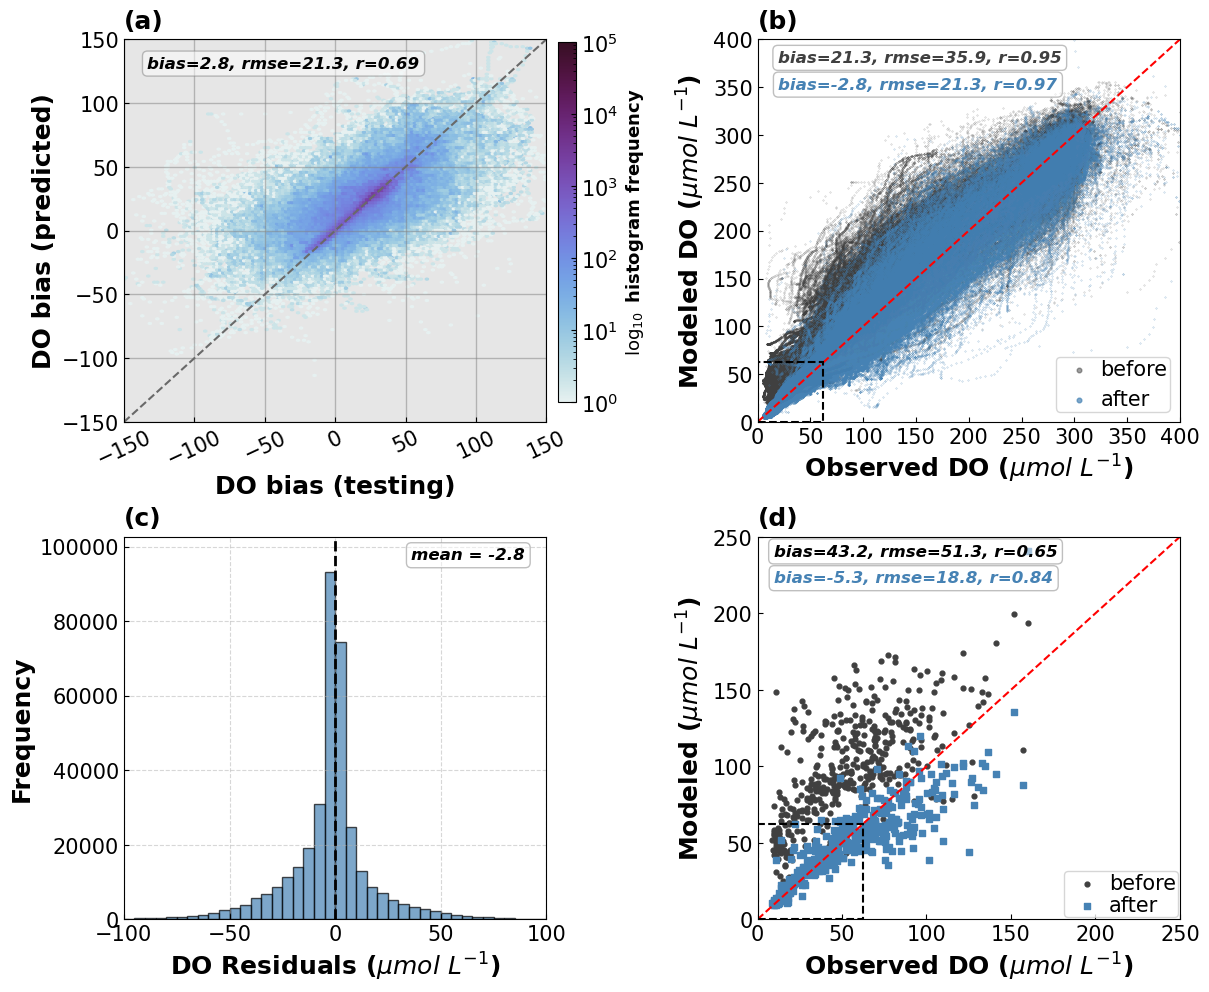

In [14]:
"""
plot all four together
"""

import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(12,10))

gs = gridspec.GridSpec(
    2, 2,
    wspace=0.5,
    hspace=0.3
)

ax1 = fig.add_subplot(gs[0,0])

ax2 = fig.add_subplot(gs[0,1])

ax3 = fig.add_subplot(gs[1,0])

ax4 = fig.add_subplot(gs[1,1])


"""
(1) 1:1 predicted bias vs testing bias
"""
bias = np.nanmean(y_pred - y_test)
RMSE = np.sqrt(np.nanmean((y_pred - y_test)**2))
bias_lim = [-150, 150]

from scipy.stats import pearsonr
r, p = pearsonr(y_test, y_pred)

ax1.plot(bias_lim, bias_lim, '--', color='dimgray', lw=1.5)
ax1.set_facecolor('#e6e6e6')

hb = ax1.hexbin(
    y_test,
    y_pred,
    gridsize=200,
    cmap=cmocean.cm.dense,
    norm=LogNorm(vmin=1, vmax=1e5),
)
"""
Colorbar for hexbin
"""
fig.subplots_adjust(
    left=0.1,
    right=0.98,
    bottom=0.08,
    top=0.96,
    wspace=0.95,   # wider gap between columns
)
# manually add colorbar axis next to ax1
pos = ax1.get_position()
cax = fig.add_axes([
    pos.x1 + 0.01,   # distance from ax1
    pos.y0 + 0.020,          # same bottom
    0.015,           # colorbar width
    0.36     # same height
])

cbar = fig.colorbar(hb, cax=cax)
cbar.set_label(r'$\log_{10}$ histogram frequency', fontsize=13)

# cbar.ax.tick_params(labelsize=11)
# divider = make_axes_locatable(ax2)
# cax = divider.append_axes("right", size="2.5%",pad= 0.05)
# cax = fig.add_subplot(gs[0,2])  # colorbar axis
# cbar.set_label('$\log_{10}$ histogram frequency', fontsize=13)



ax1.grid(True, color='gray', linewidth=1, alpha=0.5)
ax1.text(0.7, .925,
         'bias=%0.1f, rmse=%0.1f, r=%0.2f' % (bias, RMSE, r),
         transform=ax1.transAxes,
         ha='right',
         fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3',
                   facecolor='white',
                   edgecolor='gray',
                   alpha=0.5),
         fontsize=12,
         style='italic')

ax1.set_xlabel('DO bias (testing)')
ax1.set_ylabel('DO bias (predicted)')
ax1.set_xlim(bias_lim)
ax1.set_ylim(bias_lim)

ax1.set_xticks(np.arange(bias_lim[0], bias_lim[1] + 1, 50))
ax1.tick_params(axis='x', labelrotation=25)
ax1.set_yticks(np.arange(bias_lim[0], bias_lim[1] + 1, 50))

ax1.set_title('(a)', loc='left', fontsize=18, fontweight='bold', pad=8)


"""
(2) Bias corrected DO vs observed DO
"""
y_model = X_test['DO (uM)'].values
y = X_test['bias_corrected_DO'].values
x = X_test['DO_obs'].values

bias = np.nanmean(y - x)
RMSE = np.sqrt(np.nanmean((y - x)**2))
r, p = pearsonr(y, x)

original_bias = np.nanmean(y_model - x)
original_RMSE = np.sqrt(np.nanmean((y_model - x)**2))
original_r, original_p = pearsonr(y_model, x)

DO_lim = [0, 400]

hypoxia_threshold = 62.2
# Only samples where observed DO is hypoxic
hypoxic_mask = x < hypoxia_threshold
# After bias correction
RMSE_hypoxia = np.sqrt(
    np.nanmean((y[hypoxic_mask] - x[hypoxic_mask])**2)
)
r_hypoxia, p_hypoxia = pearsonr(y[hypoxic_mask], x[hypoxic_mask])
# Before bias correction
original_RMSE_hypoxia = np.sqrt(
    np.nanmean((y_model[hypoxic_mask] - x[hypoxic_mask])**2)
)
original_r_hypoxia, original_p_hypoxia = pearsonr(y_model[hypoxic_mask], x[hypoxic_mask])


print(f'Before correction RMSE (<62.2 µM), r: {original_RMSE_hypoxia:.2f} µM, {original_r_hypoxia}')
print(f'After correction RMSE (<62.2 µM), r:  {RMSE_hypoxia:.2f} µM, {r_hypoxia}')

ax2.scatter(x, y_model, alpha=0.5, color='#404040', s=0.05, label='before')
ax2.scatter(x, y, alpha=0.7,  color='steelblue',s=0.05, label='after')   # color='#E66100',

ax2.legend(markerscale=15, loc='lower right', borderpad=0.1, handletextpad=0.05)

ax2.plot(DO_lim, DO_lim, '--r', linewidth=1.5)
rect = Rectangle(
    (0, 0),                         # lower-left corner
    hypoxia_threshold,              # width
    hypoxia_threshold,              # height
    fill=False,
    edgecolor='black',
    linewidth=1.5,
    linestyle='--',
    zorder=10
)

ax2.add_patch(rect)

ax2.text(0.72, .94,
         'bias=%0.1f, rmse=%0.1f, r=%0.2f' % (original_bias, original_RMSE, original_r),
         c='#404040',
         transform=ax2.transAxes,
         ha='right',
         fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3',
                   facecolor='white',
                   edgecolor='gray',
                   alpha=0.5),
         fontsize=12,
         style='italic')
ax2.text(0.71, .87,
         'bias=%0.1f, rmse=%0.1f, r=%0.2f' % (bias, RMSE, r),
         c='steelblue', #'#E66100',
         transform=ax2.transAxes,
         ha='right',
         fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3',
                   facecolor='white',
                   edgecolor='gray',
                   alpha=0.5),
         fontsize=12,
         style='italic')


ax2.set_xlabel('Observed DO ($\mu mol\ L^{-1}$)')
ax2.set_ylabel('Modeled DO ($\mu mol\ L^{-1}$)')
ax2.set_xlim(DO_lim)
ax2.set_ylim(DO_lim)

ax2.set_xticks(np.arange(DO_lim[0], DO_lim[1] + 1, 50))
ax2.set_yticks(np.arange(DO_lim[0], DO_lim[1] + 1, 50))

ax2.set_title('(b)', loc='left', fontsize=18, fontweight='bold', pad=8)


"""
(3) Residual histogram
"""
residuals = y - x
mean = np.mean(residuals)

from scipy.stats import skew, kurtosis
print("Skewness:", skew(residuals))
print("Excess kurtosis:", kurtosis(residuals))

bin_min = np.floor(residuals.min() / 5) * 5
bin_max = np.ceil(residuals.max() / 5) * 5
bins = np.arange(bin_min, bin_max + 5, 5)

counts, bins, patches = ax3.hist(
    residuals,
    bins=bins,
    edgecolor='black',
    color='steelblue',
    alpha=0.7
)

ax3.set_ylim(0, counts.max() * 1.1)

ax3.axvline(0, color='black', linestyle='--', linewidth=2)

ax3.text(0.95, .94,
         f'mean = {mean:.1f}',
         transform=ax3.transAxes,
         ha='right',
         fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3',
                   facecolor='white',
                   edgecolor='gray',
                   alpha=0.5),
         fontsize=12,
         style='italic')

ax3.set_xlabel('DO Residuals ($\mu mol\ L^{-1}$)')
ax3.set_ylabel('Frequency')
ax3.set_xlim([-100, 100])
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.set_title('(c)', loc='left', fontsize=18, fontweight='bold', pad=8)

"""
(4) hypoxia classification,
"""

ax4.set_title('(d)',loc='left', fontsize=18, fontweight='bold', pad=8)
# get bottom trawl survey data
source = 'GroundfishTrawl'
if source == 'GroundfishTrawl':
    cid_count = X_test.groupby('cid').size()
    single_cids = cid_count[cid_count == 1].index
    single_mask = X_test['cid'].isin(single_cids).to_numpy()

    trawl_X_test = X_test.loc[single_mask].copy()  # testing X
    trawl_y_test = y_test[single_mask]  # testing y   bias
    trawl_y_pred = y_pred[single_mask]  # prediction y   bias
    trawl_DO = data['obs_DO'][single_mask]  # obs DO

    """
    add the predicted bias back to modeled DO,
    plot bias corrected DO with obs DO
    """
    y = trawl_X_test['DO (uM)'] - trawl_y_pred  # model - prediction
    x = trawl_DO   # trawl survey data


    bias = np.nanmean(y-x)
    RMSE = np.sqrt(np.nanmean((y-x)**2))
    r, p = pearsonr(y, x)

    y_model = trawl_X_test['DO (uM)'].values
    original_bias = np.nanmean(y_model-x)
    original_RMSE = np.sqrt(np.nanmean((y_model-x)**2))
    original_r, original_p = pearsonr(y_model, x)
    """ get the 1:1 plot, and calculate the r, slope, mse etc"""
    DO_lim = [0, 250]

    ax4.scatter(x,y_model,  alpha=1, color = '#404040',s = 12, label='before')
    ax4.scatter(x,y,  alpha=1, color = 'steelblue', s = 13, marker='s', label='after')
    ax4.legend(
    markerscale=1,
    loc='lower right',
    borderpad=0.1,
    labelspacing=0.1,
    handletextpad=0.05,
    borderaxespad=0.1
)
    ax4.plot(DO_lim, DO_lim, '--r', label='1:1 Line',linewidth = 1.5)  # 1:1 reference line


    ax4.text(0.71,.95,'bias=%0.1f, rmse=%0.1f, r=%0.2f' % (original_bias, original_RMSE, original_r),
              c='black', transform=ax4.transAxes, ha='right', fontweight='bold',
              bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.5),
              fontsize=12*1.0,style='italic')

    ax4.text(0.70,.88,'bias=%0.1f, rmse=%0.1f, r=%0.2f' % (bias, RMSE, r),
             c='steelblue', transform=ax4.transAxes, ha='right', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.5),
             fontsize=12*1.0,style='italic')

    hypoxic_mask = x < hypoxia_threshold
    # After bias correction
    RMSE_hypoxia = np.sqrt(
        np.nanmean((y[hypoxic_mask] - x[hypoxic_mask])**2)
    )
    r_hypoxia, p_hypoxia = pearsonr(y[hypoxic_mask], x[hypoxic_mask])
    # Before bias correction
    original_RMSE_hypoxia = np.sqrt(
        np.nanmean((y_model[hypoxic_mask] - x[hypoxic_mask])**2)
    )
    original_r_hypoxia, original_p_hypoxia = pearsonr(y_model[hypoxic_mask], x[hypoxic_mask])

    print(f'Trawl Survey Before correction RMSE (<62.2 µM), r: {original_RMSE_hypoxia:.2f} µM, {original_r_hypoxia}')
    print(f'Trawl Survey After correctio RMSE (<62.2 µM), r:  {RMSE_hypoxia:.2f} µM, {r_hypoxia}')

    rect = Rectangle(
    (0, 0),                         # lower-left corner
    hypoxia_threshold,              # width
    hypoxia_threshold,              # height
    fill=False,
    edgecolor='black',
    linewidth=1.5,
    linestyle='--',
    zorder=20
    )
    ax4.add_patch(rect)
    ax4.set_xlabel('Observed DO ($\mu mol\ L^{-1}$)')
    ax4.set_ylabel('Modeled ($\mu mol\ L^{-1}$)')
    ax4.set_xlim(DO_lim)
    ax4.set_ylim(DO_lim)

    # Set ticks every 50 units
    ax4.set_xticks(np.arange(DO_lim[0], DO_lim[1]+1, 50))
    ax4.set_yticks(np.arange(DO_lim[0], DO_lim[1]+1, 50))


# plt.tight_layout()
plt.savefig(
    f'{fig_dir}/ML_model_diagnostics_{reg}_epochs={epochs}.png',
    dpi=300
)

plt.show()